<a href="https://colab.research.google.com/github/AliPatrick71/AI-Science-Engineering/blob/main/week6_unsupervised_machine_learning_bitcoin_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 Assignment: Unsupervised Machine Learning
## AI for Science and Engineering — Discovering Bitcoin Market Regimes

### Project question
Can clustering identify different types of Bitcoin market conditions from historical 15-minute price and trading-volume data?

Unlike supervised learning, **unsupervised learning does not use a target label to train the model**. K-Means will group observations based on similarities in selected numerical features. The groups may represent different market regimes, such as quieter periods or periods with larger price movements and trading activity.


## 1. Load the Bitcoin dataset

We use 15-minute BTC-USD OHLCV data. Features are calculated from current and past observations only. The downloaded data and resulting cluster assignments may vary over time.

In [1]:
%pip -q install yfinance scikit-learn

In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

raw = yf.download(
    "BTC-USD",
    period="60d",
    interval="15m",
    auto_adjust=False,
    progress=False
)

if raw.empty:
    raise ValueError(
        "No data was downloaded. Check your internet connection, or load the "
        "same BTC-USD OHLCV CSV dataset you used in Week 3."
    )

if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)

raw = raw.reset_index()
raw.columns = [str(c).lower().replace(" ", "_") for c in raw.columns]

required = ["open", "high", "low", "close", "volume"]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

print("Dataset shape:", raw.shape)
display(raw.head())

Dataset shape: (5727, 7)


,datetime,adj_close,close,high,low,open,volume
0,2026-08-29 00:00:00+00:00,77812.476562,77812.476562,77870.937500,77781.210938,77839.187500,120557568
1,2026-08-29 00:15:00+00:00,77901.671875,77901.671875,77950.312500,77808.687500,77812.476562,120414208
2,2026-08-29 00:30:00+00:00,77784.750000,77784.750000,77897.703125,77767.648438,77897.703125,88735744
3,2026-08-29 00:45:00+00:00,77734.476562,77734.476562,77819.398438,77715.742188,77784.742188,0
4,2026-08-29 01:00:00+00:00,77632.781250,77632.781250,77724.992188,77631.023438,77717.867188,0


## 2. Select and prepare features

I will group observations using three features:
- **Absolute 1-period return:** size of the latest 15-minute price change, regardless of direction.
- **4-period return:** price change across approximately one hour.
- **Volume:** amount traded during the 15-minute interval.

Absolute return helps describe how large the price movement was, while the 4-period return provides short-term direction and volume describes trading activity. We apply `log1p` to volume to reduce the influence of very large values, then standardize all features so that variables with larger numerical scales do not dominate the distance calculations.

I did not include a target column because clustering is unsupervised.

In [3]:
data = raw.copy()
data["return_1"] = data["close"].pct_change()
data["abs_return_1"] = data["return_1"].abs()
data["return_4"] = data["close"].pct_change(4)
data["log_volume"] = np.log1p(data["volume"].clip(lower=0))

feature_columns = ["abs_return_1", "return_4", "log_volume"]
cluster_data = data.dropna(subset=feature_columns).copy()
cluster_data = cluster_data.replace([np.inf, -np.inf], np.nan).dropna(subset=feature_columns)

X = cluster_data[feature_columns]
print("Rows available for clustering:", len(X))
display(X.describe().round(6))

Rows available for clustering: 5723


,abs_return_1,return_4,log_volume
count,5723.000000,5723.000000,5723.000000
mean,0.001169,0.000028,15.026592
std,0.001327,0.003541,7.340114
min,0.000000,-0.025160,0.000000
25%,0.000352,-0.001523,16.591931
50%,0.000783,0.000037,18.321913
75%,0.001544,0.001597,19.150110
max,0.020148,0.032680,22.268024


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features standardized. Means (approximately 0):", X_scaled.mean(axis=0).round(3))
print("Features standardized. Standard deviations (approximately 1):", X_scaled.std(axis=0).round(3))

Features standardized. Means (approximately 0): [ 0.  0. -0.]
Features standardized. Standard deviations (approximately 1): [1. 1. 1.]


## 3. Explore different numbers of clusters

K-Means requires us to choose the number of clusters, \(k\). We will compare \(k=2\) through \(k=6\) using:
- **Inertia:** the sum of squared distances to each assigned cluster centre. It generally decreases as \(k\) increases, so look for a point where improvement begins to slow (the elbow).
- **Silhouette score:** compares how close each observation is to its own cluster versus other clusters. Scores closer to +1 indicate better-separated clusters, values around 0 indicate overlapping clusters, and negative values can indicate questionable assignments.

Neither measure alone proves that the clusters are meaningful. We will use the scores and interpretability together.

In [5]:
candidate_k = range(2, 7)
evaluation_rows = []
models = {}

# Silhouette sampling keeps calculation practical on larger datasets.
rng = np.random.RandomState(42)
sample_size = min(5000, len(X_scaled))
sample_indices = rng.choice(len(X_scaled), size=sample_size, replace=False)
X_silhouette = X_scaled[sample_indices]

for k in candidate_k:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_scaled)
    models[k] = model
    score = silhouette_score(X_silhouette, labels[sample_indices])
    evaluation_rows.append({
        "k (number of clusters)": k,
        "inertia": model.inertia_,
        "silhouette_score": score
    })

evaluation = pd.DataFrame(evaluation_rows).set_index("k (number of clusters)")
display(evaluation.round(4))

,inertia,silhouette_score
k (number of clusters),,
2,11546.5629,0.5100
3,8664.1740,0.5242
4,6654.1755,0.5155
5,5673.6703,0.4332
6,4880.7929,0.4091


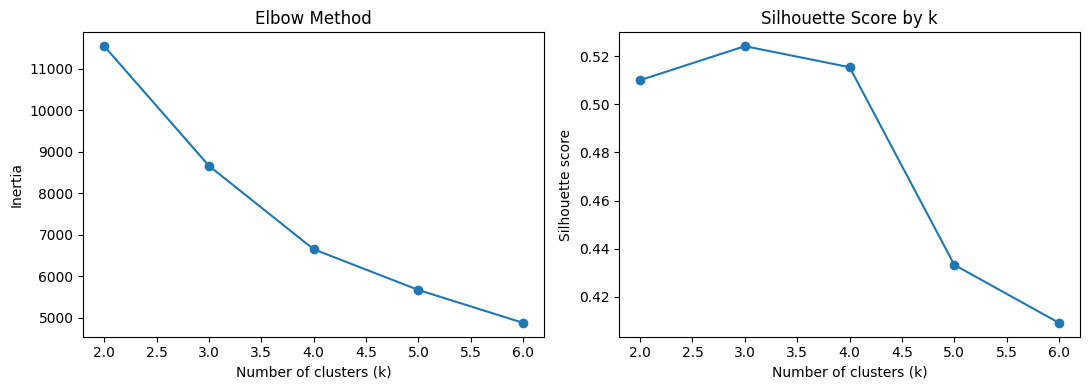

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(evaluation.index, evaluation["inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(evaluation.index, evaluation["silhouette_score"], marker="o")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

### Choose the number of clusters

The next cell selects the \(k\) with the highest silhouette score among the tested values \(2\)–\(6\). Review the elbow plot and cluster summaries too: if the best score is only marginally higher than alternatives, prefer a simpler solution that is easier to explain. The selected value is a practical exploratory choice, not a universal truth.

In [7]:
best_k = int(evaluation["silhouette_score"].idxmax())
best_model = models[best_k]
cluster_data["cluster"] = best_model.labels_

print(f"Selected k based on the highest tested silhouette score: {best_k}")
print("Silhouette score:", round(evaluation.loc[best_k, "silhouette_score"], 4))
display(cluster_data["cluster"].value_counts().sort_index().rename("observations").to_frame())

Selected k based on the highest tested silhouette score: 3
Silhouette score: 0.5242


,observations
cluster,
0,1061
1,657
2,4005


## 4. Visualize the clusters

We use Principal Component Analysis (PCA) to project the three standardized features into two dimensions for a plot. PCA is used here for visualization; K-Means was fitted on the full three-feature standardized data, not on the two-dimensional plot.

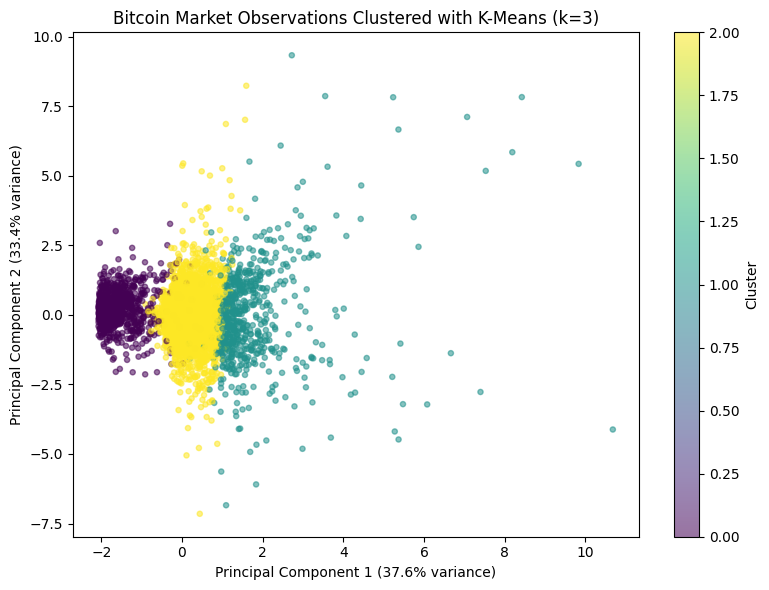

Total variance represented by the two plotted components: 71.0%


In [8]:
pca = PCA(n_components=2, random_state=42)
components = pca.fit_transform(X_scaled)

plot_data = pd.DataFrame({
    "PC1": components[:, 0],
    "PC2": components[:, 1],
    "cluster": cluster_data["cluster"].to_numpy()
})

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    plot_data["PC1"], plot_data["PC2"],
    c=plot_data["cluster"], cmap="viridis",
    alpha=0.55, s=14
)
plt.title(f"Bitcoin Market Observations Clustered with K-Means (k={best_k})")
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

print("Total variance represented by the two plotted components:",
      f"{pca.explained_variance_ratio_.sum():.1%}")

## 5. Describe the groups identified by the model

To interpret each group, I compared the original features rather than relying only on the cluster colours. The tables below show the mean and median of each clustering feature, together with the number of observations in each cluster. The features are the absolute 15-minute price return (`abs_return_1`), the four-period price return (`return_4`), and the logarithmically transformed trading volume (`log_volume`). Because volume was transformed using `log1p`, its feature summary is expressed in log-volume units. A second table presents trading volume in its original units for easier interpretation.

### Cluster feature summary

| Cluster | Observations | Absolute 15-minute return (mean) | Absolute 15-minute return (median) | Four-period return (mean) | Four-period return (median) | Log volume (mean) | Log volume (median) |
|---|---:|---:|---:|---:|---:|---:|---:|
| 0 | 1,061 | 0.000842 | 0.000587 | 0.000110 | 0.000120 | 0.008222 | 0.000000 |
| 1 | 657 | 0.003853 | 0.003253 | -0.000503 | -0.000711 | 18.522333 | 19.057516 |
| 2 | 4,005 | 0.000816 | 0.000689 | 0.000094 | 0.000062 | 18.431783 | 18.584837 |

The absolute 15-minute return measures the size of the price movement without considering whether the price increased or decreased. The four-period return measures the direction and magnitude of the price change over approximately one hour. Positive values indicate upward movement, while negative values indicate downward movement.

### Trading volume in its original units

| Cluster | Median absolute 15-minute return | Median four-period return | Median trading volume | Mean trading volume |
|---|---:|---:|---:|---:|
| 0 | 0.000587 | 0.000120 | 0 | 5.79 |
| 1 | 0.003253 | -0.000711 | 189,048,832 | 367,459,200 |
| 2 | 0.000689 | 0.000062 | 117,839,872 | 197,194,200 |

*Note: Trading volume is reported in the units supplied by the dataset. The values are not percentages. The small mean volume in Cluster 0 and its zero median indicate that zero-volume observations are a defining characteristic of this group.*

### Interpretation of the identified groups

**Cluster 0: Low price movement and zero median volume**

Cluster 0 contains 1,061 observations. Its median absolute 15-minute return is 0.000587 (approximately 0.0587%), and its median four-period return is 0.000120 (approximately +0.0120%). Both values indicate relatively small price movements. However, its median trading volume is zero, and its mean trading volume is only 5.79 in the dataset's original volume units. This group therefore appears to contain observations with low price movement and zero or extremely low reported trading volume. The zero-volume values should be investigated to determine whether they represent genuine observations or a data-quality issue.

**Cluster 1: Higher volatility and negative short-term returns**

Cluster 1 contains 657 observations, making it the smallest group. It has the highest median absolute 15-minute return, at 0.003253 (approximately 0.3253%), and the highest mean absolute return, at 0.003853. Its median four-period return is -0.000711 (approximately -0.0711%), indicating a slight downward tendency over approximately one hour. Its median trading volume is 189,048,832, while its mean is 367,459,200. These characteristics suggest that Cluster 1 represents periods of relatively high price volatility, a negative median short-term return, and comparatively high trading volume. However, the negative median does not mean that every observation experienced a price decline.

**Cluster 2: Relatively low volatility and slightly positive returns**

Cluster 2 contains 4,005 observations, making it the largest group. Its median absolute 15-minute return is 0.000689 (approximately 0.0689%), while its median four-period return is 0.000062 (approximately +0.0062%). These values indicate relatively small price movements and a nearly flat but slightly positive median return. Its median trading volume is 117,839,872, and its mean is 197,194,200. This group can therefore be interpreted as a relatively low-volatility pattern with positive median short-term returns and substantial reported trading volume. Since it accounts for approximately 70% of the observations, this pattern is the most common among the observations analyzed.

The feature summaries indicate that the three clusters differ mainly in their price-movement magnitudes, short-term return direction, and trading volume. Cluster 1 is distinguished by larger price movements and negative median returns, while Cluster 2 contains most observations with smaller price movements and positive median returns. Cluster 0 is distinguished particularly by its zero median trading volume. These interpretations describe patterns in the historical data; they do not establish causal relationships or guarantee future market behaviour.

In [9]:
cluster_summary = cluster_data.groupby("cluster")[feature_columns].agg(["mean", "median"])
cluster_sizes = cluster_data["cluster"].value_counts().sort_index().rename("count")
display(cluster_sizes.to_frame())
display(cluster_summary.round(6))

raw_volume_summary = cluster_data.groupby("cluster").agg(
    median_abs_15m_return=("abs_return_1", "median"),
    median_4_period_return=("return_4", "median"),
    median_volume=("volume", "median"),
    mean_volume=("volume", "mean")
)
display(raw_volume_summary.round(6))

,count
cluster,
0,1061
1,657
2,4005


abs_return_1            return_4           log_volume           
                mean    median      mean    median       mean     median
cluster                                                                 
0           0.000842  0.000587  0.000110  0.000120   0.008222   0.000000
1           0.003853  0.003253 -0.000503 -0.000711  18.522333  19.057516
2           0.000816  0.000689  0.000094  0.000062  18.431783  18.584837

,median_abs_15m_return,median_4_period_return,median_volume,mean_volume
cluster,,,,
0,0.000587,0.000120,0.0,5.790763e+00
1,0.003253,-0.000711,189048832.0,3.674592e+08
2,0.000689,0.000062,117839872.0,1.971942e+08


In [10]:

overall_medians = cluster_data[["abs_return_1", "return_4", "volume"]].median()
chosen_silhouette = float(evaluation.loc[best_k, "silhouette_score"])

print(f"Selected number of clusters: {best_k}")
print(f"Silhouette score (sampled evaluation): {chosen_silhouette:.3f}")

if chosen_silhouette < 0.25:
    print("Separation interpretation: weak. The clusters may overlap substantially, "
          "so treat them as exploratory groupings rather than clearly distinct regimes.")
elif chosen_silhouette < 0.50:
    print("Separation interpretation: modest. Some structure may be present, but "
          "groups likely overlap or are not sharply separated.")
else:
    print("Separation interpretation: relatively stronger than lower scores, although "
          "the plot and feature summaries should still be checked for overlap.")

print("\\nData-driven descriptions of the groups:")
for cluster_id, row in raw_volume_summary.iterrows():
    parts = []

    abs_med = row["median_abs_15m_return"]
    if abs_med < overall_medians["abs_return_1"]:
        parts.append("smaller-than-overall-median 15-minute price movements")
    else:
        parts.append("larger-than-or-equal-to-overall-median 15-minute price movements")

    ret_med = row["median_4_period_return"]
    if ret_med > 0:
        parts.append("a positive median return over four intervals (about one hour)")
    elif ret_med < 0:
        parts.append("a negative median return over four intervals (about one hour)")
    else:
        parts.append("a median four-interval return around zero")

    vol_med = row["median_volume"]
    if vol_med < overall_medians["volume"]:
        parts.append("below-overall-median trading volume")
    else:
        parts.append("at-or-above-overall-median trading volume")

    count = int(cluster_sizes.loc[cluster_id])
    print(f"\\nCluster {cluster_id} ({count:,} observations): " + "; ".join(parts) + ".")

print("\\nPlot-overlap check:")
print("Inspect the PCA scatter plot above. If colours intermingle heavily rather than "
      "forming visibly separate regions, state that the clusters overlap in the 2D "
      "visualization. PCA is only a projection of the original three-feature data, "
      "so the plot is a useful view but not a complete test of separation.")

Selected number of clusters: 3
Silhouette score (sampled evaluation): 0.524
Separation interpretation: relatively stronger than lower scores, although the plot and feature summaries should still be checked for overlap.
\nData-driven descriptions of the groups:
\nCluster 0 (1,061 observations): smaller-than-overall-median 15-minute price movements; a positive median return over four intervals (about one hour); below-overall-median trading volume.
\nCluster 1 (657 observations): larger-than-or-equal-to-overall-median 15-minute price movements; a negative median return over four intervals (about one hour); at-or-above-overall-median trading volume.
\nCluster 2 (4,005 observations): smaller-than-overall-median 15-minute price movements; a positive median return over four intervals (about one hour); at-or-above-overall-median trading volume.
\nPlot-overlap check:
Inspect the PCA scatter plot above. If colours intermingle heavily rather than forming visibly separate regions, state that the c

# Discussion of Bitcoin Market Clusters Using Unsupervised Learning

## Selected Number of Clusters and Silhouette Score

The K-Means algorithm selected **three clusters (k = 3)** as the best option among the five tested values of k, ranging from 2 to 6. The selection was based on the highest silhouette score, which was **0.5242**. The silhouette score measures how well observations fit within their assigned clusters compared with other clusters. This score suggests that the dataset contains a reasonably identifiable clustering structure, although it does not indicate perfect separation.

The analysis used 5,723 Bitcoin market observations collected at 15-minute intervals. Three features were used for clustering: the absolute 15-minute price return, the four-period price return (approximately one hour), and the logarithmically transformed trading volume. These features were standardized before applying K-Means so that differences in their numerical scales would not dominate the clustering process.

## Interpretation of the Three Clusters

**Cluster 0: Low price movement and zero median trading volume**

Cluster 0 contained **1,061 observations**. Its median absolute 15-minute return was 0.000587, equivalent to approximately **0.0587%**. Its median four-period return was 0.000120, or approximately **+0.0120%**, indicating a very small positive price movement over approximately one hour. The most notable characteristic was its median trading volume of **zero**.

These results suggest that Cluster 0 primarily represents observations with relatively small short-term price movements and zero reported trading volume. The zero median volume is important: it means that at least half of the observations in this cluster had zero volume. Therefore, this group should not automatically be interpreted as a normal low-activity market regime. The zero-volume values may reflect the characteristics or limitations of the downloaded data and should be investigated before drawing conclusions about actual market activity.

**Cluster 1: Higher volatility and a negative short-term return**

Cluster 1 contained **657 observations**, making it the smallest of the three clusters. Its median absolute 15-minute return was 0.003253, equivalent to approximately **0.3253%**. This was substantially higher than the corresponding medians for the other two clusters. Its median four-period return was −0.000711, or approximately **−0.0711%**, while its median trading volume was **189,048,832**.

These feature summaries suggest that Cluster 1 represents periods of relatively large short-term price movements, accompanied by a small negative median return over approximately one hour and comparatively high trading volume. It could be interpreted as a **higher-volatility market pattern with a slight downward short-term tendency**. However, the negative median return does not mean that every observation in this cluster experienced a price decline. Similarly, the cluster's characteristics do not establish that high trading volume caused the larger price movements.

**Cluster 2: Low price movement and positive short-term returns**

Cluster 2 was the largest group, containing **4,005 observations**. Its median absolute 15-minute return was 0.000689, or approximately **0.0689%**. Its median four-period return was 0.000062, equivalent to approximately **+0.0062%**, and its median trading volume was **117,839,872**.

These results suggest that Cluster 2 represents periods of relatively small short-term price movements, slightly positive median returns, and substantial reported trading volume. Compared with Cluster 1, this group exhibited much smaller typical price movements. It may therefore be described as a **relatively low-volatility pattern with a nearly flat but slightly positive short-term return**. Because this cluster contains approximately 70% of the observations, these characteristics were common in the analyzed dataset.

## PCA Visualization and Cluster Overlap

Principal Component Analysis (PCA) was used to visualize the clusters in two dimensions. The first principal component explained **37.6%** of the variance, while the second explained **33.4%**. Together, the two components represented **71.0%** of the variance in the standardized features.

The scatter plot shows some visible separation among the clusters. Cluster 0 is concentrated mainly on the left side of the plot, Cluster 2 occupies much of the central region, and Cluster 1 extends farther to the right and contains a broader spread of observations. This pattern is consistent with the feature summaries, particularly the higher absolute returns associated with Cluster 1.

However, the plot also shows overlap, especially around the boundaries between the central and right-hand groups. The clusters are not completely separated into independent regions, and some observations occupy similar positions in the two-dimensional projection. Furthermore, PCA preserves only 71.0% of the variance in the displayed components, so the plot does not capture all the information used by K-Means in the original three-dimensional feature space.

The silhouette score of 0.5242 supports the interpretation that the clustering has some meaningful structure, but the visual overlap cautions against treating the groups as completely distinct market conditions.


## 6. Conclusion

This notebook applies **K-Means clustering**, an unsupervised learning method, to discover possible groups in Bitcoin market observations without using labelled target outcomes. We standardized the features, compared multiple cluster counts using inertia and silhouette score, selected a candidate number of clusters, visualized the result using PCA, and examined the characteristics of each group.

The unsupervised learning analysis identified three groups with different characteristics. Cluster 0 was associated with small price movements and a zero median trading volume; Cluster 1 was characterized by substantially larger price movements, a negative median four-period return, and high trading volume; and Cluster 2 contained the majority of observations and exhibited relatively small price movements with a slightly positive median four-period return.

The results demonstrate how K-Means can help organize Bitcoin market observations into groups based on similarities in price movements and trading volume. Nevertheless, the clusters are exploratory rather than definitive market regimes. The PCA plot shows some overlap, and the zero-volume observations in Cluster 0 warrant additional data-quality checks. Consequently, the findings reveal potentially useful structure in the dataset, but they do not establish that the groups are naturally occurring, predict future prices, or provide a reliable trading strategy.